# Figure 4 — prior calibration on GSM8K

Editable exploratory figure: blue uses the 1,536-example manifest in `equalized_3b_1536_v1` (a prefix of the assembled comparison stream, **not native GSM8K order**). No validation overlay. Whiskers are pointwise paired-bootstrap **90% intervals (5th–95th percentiles)**, with 10,000 draws and seed 42. Scoring uses numeric + conservative unit normalization.

The random control must use the identical question/prompt pairs. Until that run finishes, this notebook reproduces the existing plot with the historical 1,024-example red control **explicitly marked provisional/unmatched**. Set `ALLOW_PROVISIONAL_CONTROL=False` to prevent publication exports with that fallback.

Style defaults follow the paper's `fig3_split_switch_control.ipynb` (8-inch width) and `fig5_entropy_causality.ipynb` (11–12 pt labels, 9 pt legend). Height is adapted for a single panel. All settings are editable below.


In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

candidates = [Path.cwd(), Path.cwd() / "prior_calibration", Path.cwd().parent / "prior_calibration"]
ROOT = next((p for p in candidates if (p / "data/second_batch_1536_whiskers_90ci.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from notebook_plotters, prior_calibration, or the repository root.")
DATA = ROOT / "data"
OUT = ROOT / "plot_export"
ALLOW_PROVISIONAL_CONTROL = True
EXPORT = True
STYLE = dict(
    figsize=(8, 4.8), dpi=200, font_family="DejaVu Sans",
    base_font=10, title_font=11, xlabel_font=11, ylabel_font=12,
    tick_font=10, legend_font=9, region_font=10, note_font=8,
    blue="#336b8d", red="#c83232", shade_alpha=0.055,
    blue_linewidth=2.5, red_linewidth=1.8, marker_size=4.5,
    whisker_width=1.1, cap_size=3, xlim=(0.5, 1.2), ylim=None,
    show_title=True, show_region_labels=True, show_grid=True,
    show_whiskers=True, show_caption=True,
)
plt.rcParams.update({
    "font.family": STYLE["font_family"], "font.size": STYLE["base_font"],
    "xtick.labelsize": STYLE["tick_font"], "ytick.labelsize": STYLE["tick_font"],
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


## Data and paired intervals

Each problem contributes +1 if corrected, −1 if broken, or 0 if correctness is unchanged. Resample whole problem pairs, not baseline and tuned outcomes independently. The plotted endpoints are actual percentiles, not symmetrized. These intervals do not adjust for alpha selection, subset selection, or multiple comparisons. The historical snapshot is frozen; matched-control data replace red only after all requested settings complete.


In [2]:
snapshot = json.loads((DATA / "second_batch_1536_whiskers_90ci.json").read_text())
blue = snapshot["blue"]
matched_root = ROOT / "random_direction_3b_1536_v1"
matched = (matched_root / "complete.json").exists()

if matched:
    sys.path.insert(0, str(ROOT))
    from helpers import rescore_units as scoring
    manifest = json.loads((matched_root / "manifest.json").read_text())
    fitted_manifest = json.loads((ROOT / "equalized_3b_1536_v1/manifest.json").read_text())
    examples = manifest["examples"]
    assert [r["question_sha256"] for r in examples] == [r["question_sha256"] for r in fitted_manifest["examples"]]
    baseline = scoring.arm(matched_root / "3b", 1., examples)
    fitted_baseline = scoring.arm(ROOT / "equalized_3b_1536_v1", 1., examples)
    assert [(r["question_sha256"], r["prompt_sha256"]) for r in baseline] == [(r["question_sha256"], r["prompt_sha256"]) for r in fitted_baseline]
    red = []
    for a in np.arange(10, 25) / 20:
        tuned = scoring.arm(matched_root / "3b", float(a), examples)
        row = dict(alpha=float(a), **scoring.paired(baseline, tuned, "unit_aware"))
        d = np.array([int(t["score"]["unit_aware"]) - int(b["score"]["unit_aware"]) for b,t in zip(baseline,tuned)])
        rng = np.random.default_rng(42)
        draws = np.concatenate([d[rng.integers(0,len(d),(100,len(d)))].mean(1) for _ in range(100)])
        row["ci90"] = np.quantile(draws, [.05,.95]).tolist()
        red.append(row)
    control_label = "Random direction (matched n = 1,536)"
    status_note = "Matched questions/prompts; separate runtime baseline; one random seed, not norm-matched."
else:
    if not ALLOW_PROVISIONAL_CONTROL:
        raise RuntimeError("Matched 1,536-example random sweep is not complete. Publication export blocked.")
    red = snapshot["red"]
    control_label = "Random direction (n = 1,024; provisional/unmatched)"
    status_note = "PROVISIONAL: red uses different examples (n=1,024) and its own cloud baseline."

assert all(r["n"] == 1536 for r in blue)
for rows in [blue,red]:
    assert all("ci90" in r for r in rows)
    assert all(r["ci90"][0] <= r["difference"] <= r["ci90"][1] for r in rows)
print(status_note)
print("At alpha=0.65:", {k: next(r for r in rows if r["alpha"] == .65) for k,rows in [("blue",blue),("red",red)]})


Matched questions/prompts; separate runtime baseline; one random seed, not norm-matched.
At alpha=0.65: {'blue': {'alpha': 0.65, 'n': 1536, 'baseline_correct': 1347, 'tuned_correct': 1374, 'difference': 0.017578125, 'ci95': [0.004557291666666667, 0.029964192708333098], 'corrected': 66, 'broken': 39, 'p': 0.010817905625818625, 'ci90': [0.006510416666666667, 0.027994791666666668]}, 'red': {'alpha': 0.65, 'n': 1536, 'baseline_correct': 1347, 'tuned_correct': 1343, 'difference': -0.0026041666666666665, 'ci95': [-0.007161458333333333, 0.001953125], 'corrected': 4, 'broken': 8, 'p': 0.3876953125, 'ci90': [-0.006510416666666667, 0.0013020833333333333]}}


## Draw and export

Edit `STYLE`, rerun the style cell, then rerun this cell. Axis limits are optional; the automatic range includes all visible interval endpoints. Missing settings are left as gaps. The editable vector PDF and high-resolution PNG use a separate filename, preserving earlier plots.


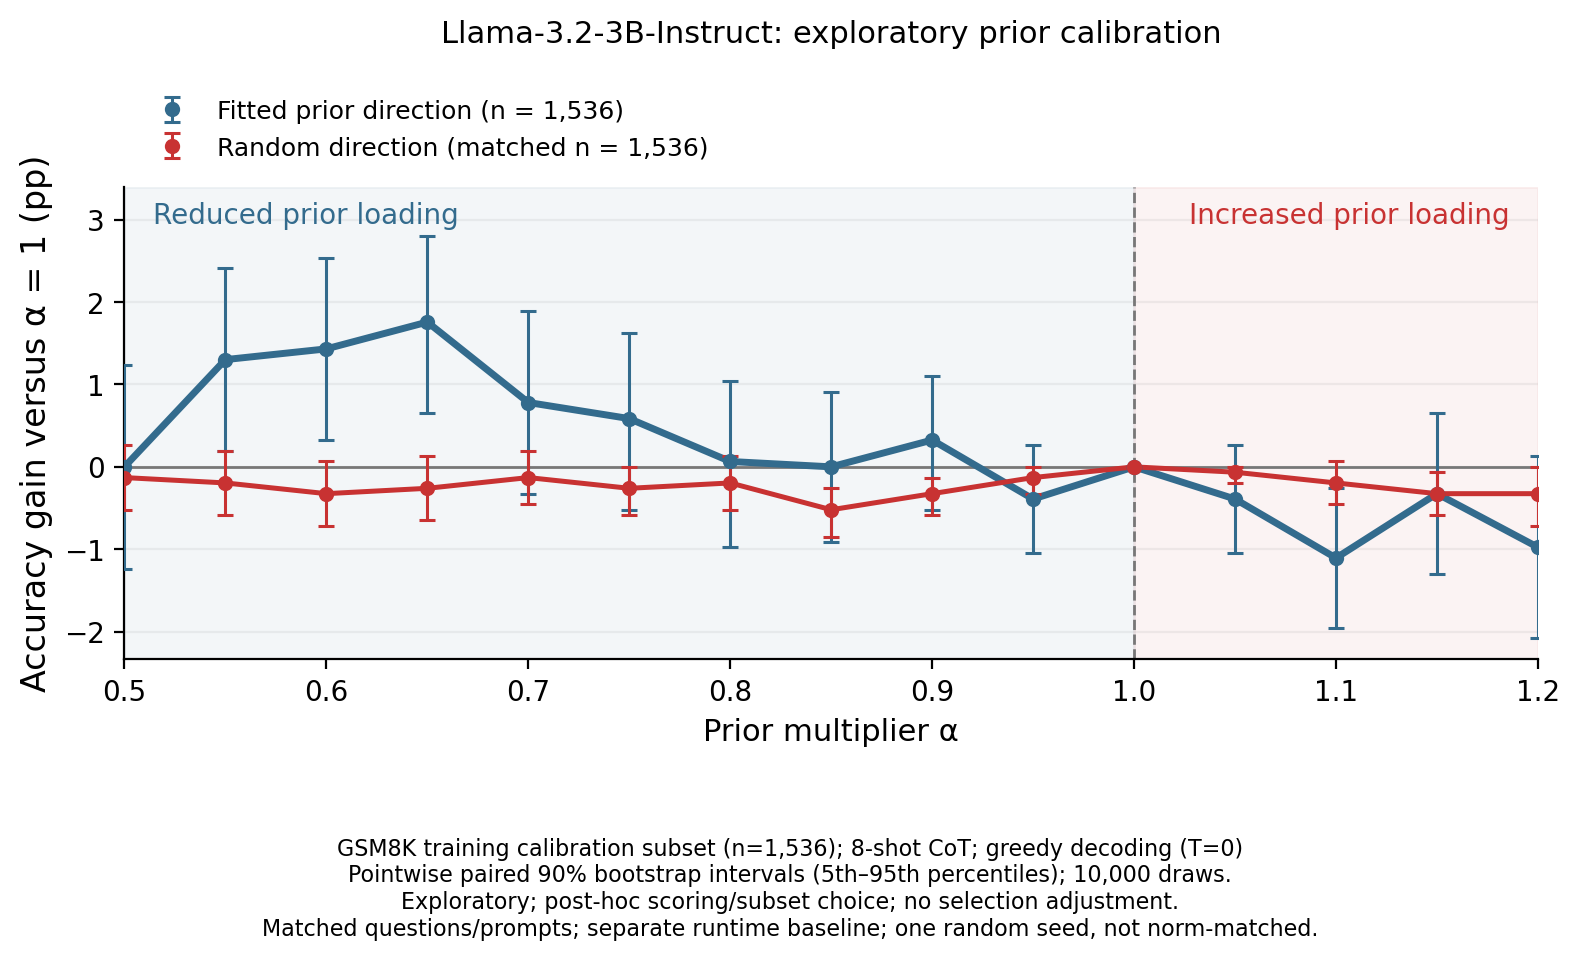

In [3]:
fig, ax = plt.subplots(figsize=STYLE["figsize"], dpi=STYLE["dpi"])
ax.axvspan(STYLE["xlim"][0], 1, color=STYLE["blue"], alpha=STYLE["shade_alpha"], zorder=0)
ax.axvspan(1, STYLE["xlim"][1], color=STYLE["red"], alpha=STYLE["shade_alpha"], zorder=0)
ax.axhline(0, color="#777777", lw=1)
ax.axvline(1, color="#777777", ls="--", lw=1)
endpoints = []
def curve(rows, color, label, linewidth):
    lookup = {round(r["alpha"],2): r for r in rows}
    grid = np.arange(25)/20
    ax.plot(grid, [100*lookup[round(a,2)]["difference"] if round(a,2) in lookup else np.nan for a in grid],
            color=color, lw=linewidth, zorder=3)
    shown = [r for r in rows if STYLE["xlim"][0] <= r["alpha"] <= STYLE["xlim"][1]]
    x = np.array([r["alpha"] for r in shown])
    y = 100*np.array([r["difference"] for r in shown])
    ci = 100*np.array([r["ci90"] for r in shown])
    endpoints.extend(ci.ravel())
    ax.errorbar(x,y,yerr=[y-ci[:,0],ci[:,1]-y] if STYLE["show_whiskers"] else None,
        fmt="o",color=color,ms=STYLE["marker_size"],elinewidth=STYLE["whisker_width"],
        capsize=STYLE["cap_size"],capthick=STYLE["whisker_width"],label=label,zorder=4)

curve(blue, STYLE["blue"], "Fitted prior direction (n = 1,536)", STYLE["blue_linewidth"])
curve(red, STYLE["red"], control_label, STYLE["red_linewidth"])
ax.set_xlim(*STYLE["xlim"])
ax.set_ylim(*(STYLE["ylim"] or (min(endpoints)-.25,max(endpoints)+.6)))
ax.set_xlabel("Prior multiplier α", fontsize=STYLE["xlabel_font"])
ax.set_ylabel("Accuracy gain versus α = 1 (pp)", fontsize=STYLE["ylabel_font"])
ax.set_xticks(np.arange(.5,1.21,.1))
if STYLE["show_region_labels"]:
    ax.text(.02,.97,"Reduced prior loading",transform=ax.transAxes,va="top",color=STYLE["blue"],fontsize=STYLE["region_font"])
    ax.text(.98,.97,"Increased prior loading",transform=ax.transAxes,va="top",ha="right",color=STYLE["red"],fontsize=STYLE["region_font"])
if STYLE["show_title"]:
    ax.set_title("Llama-3.2-3B-Instruct: exploratory prior calibration",fontsize=STYLE["title_font"],pad=52)
ax.legend(loc="lower left",bbox_to_anchor=(0,1.01),frameon=False,fontsize=STYLE["legend_font"])
ax.grid(axis="y",alpha=.18,visible=STYLE["show_grid"])
ax.spines[["top","right"]].set_visible(False)
caption = ("GSM8K training calibration subset (n=1,536); 8-shot CoT; greedy decoding (T=0)\n"
           "Pointwise paired 90% bootstrap intervals (5th–95th percentiles); 10,000 draws.\n"
           "Exploratory; post-hoc scoring/subset choice; no selection adjustment.\n" + status_note)
if STYLE["show_caption"]:
    fig.text(.5,.015,caption,ha="center",fontsize=STYLE["note_font"])
fig.tight_layout(rect=(0,.18 if STYLE["show_caption"] else 0,1,1))
if EXPORT:
    suffix = "" if matched else "_provisional"
    for ext in ["png","pdf"]:
        fig.savefig(OUT / f"fig4_prior_calibration_math{suffix}.{ext}",
                    dpi=STYLE["dpi"],bbox_inches="tight",pad_inches=.15)
plt.show()


## Paper caption draft

**Exploratory prior calibration on GSM8K.** Accuracy gain relative to the unmodified model (α=1) for Llama-3.2-3B-Instruct under greedy 8-shot CoT decoding. Blue varies the loading along the fitted prior direction; red varies loading along one fixed random direction. Shading distinguishes reduced and increased loading. Whiskers show pointwise paired-bootstrap 90% intervals (10,000 resamples). The subset and presentation were selected after inspection; intervals are not selection-adjusted. **Only describe red as matched after the matched 1,536-example control completes.**


## Path divergence: every corrected problem at α=0.65

This section includes **all** baseline-wrong → tuned-correct cases in the exact 1,536-example Figure 4 manifest, using the same numeric/conservative-unit scoring as the curve. Cases are kept in manifest order, with no example selection.

Black text is the prefix before the first differing token. Red text includes the first differing token and **12 following tokens** in each completion (or the available remainder if shorter). The complete shared prefix is retained. Any text after the cutoff is omitted, even though correctness is assessed using the full completion.

**Tokenization caveat:** the saved runs contain decoded text and token counts, not actual generated token IDs. Positions are recovered by re-tokenizing with the original Llama-3B tokenizer, without special tokens. Stripped stop tokens and decoding can prevent exact reconstruction of the original generation sequence. This view does not itself establish the cause of the divergent reasoning.



In [4]:
from IPython.display import HTML, display
from html import escape

DIVERGENCE_PATH = ROOT / "fig4_divergence_1536_v1/pairs.json"
audit = json.loads(DIVERGENCE_PATH.read_text())
pairs = audit["pairs"]
assert audit["n"] == 1536 and len(pairs) == audit["corrected"]
assert len({p["question_sha256"] for p in pairs}) == len(pairs)
assert all(not p["baseline"]["score"]["unit_aware"] and p["tuned"]["score"]["unit_aware"] for p in pairs)
assert [p["position"] for p in pairs] == sorted(p["position"] for p in pairs)
print(f'{len(pairs)} corrected pairs; {audit["broken"]} broken; net +{len(pairs)-audit["broken"]} problems.')
print(audit["tokenization"])



66 corrected pairs; 39 broken; net +27 problems.
Recovered by re-tokenizing saved response text, not recorded generation token IDs


In [5]:
# Editable display settings. None means show every corrected pair.
TOKENS_AFTER_FIRST_DIVERGENCE = 12
MAX_CASES = None
TRACE_FONT_SIZE = 13
TRACE_LINE_HEIGHT = 1.5
PREFIX_COLOR = "#000000"
DIVERGENCE_COLOR = "#c83232"
SHOW_REFERENCE_SOLUTION = False

assert TOKENS_AFTER_FIRST_DIVERGENCE >= 0

def trace_html(arm, k):
    ids, offsets, text = arm["token_ids"], arm["offsets"], arm["response"]
    start = offsets[k][0] if k < len(ids) else len(text)
    stop_token = min(len(ids), k + 1 + TOKENS_AFTER_FIRST_DIVERGENCE)
    end = offsets[stop_token-1][1] if stop_token > k else start
    before, after = text[:start], text[start:end]
    ended = '<span style="color:#777"> [end of saved completion]</span>' if end == len(text) else '<span style="color:#777"> … [remainder omitted]</span>'
    if k == len(ids):
        ended = '<span style="color:' + DIVERGENCE_COLOR + '">[end of saved completion]</span>'
    return (f'<pre style="white-space:pre-wrap;overflow-wrap:anywhere;font-size:{TRACE_FONT_SIZE}px;'
            f'line-height:{TRACE_LINE_HEIGHT};padding:12px;background:#fafafa;border:1px solid #ddd;">'
            f'<span style="color:{PREFIX_COLOR}">{escape(before)}</span>'
            f'<span style="color:{DIVERGENCE_COLOR}">{escape(after)}</span>{ended}</pre>')

parts = ['<div style="color:#000;background:#fff;padding:12px;font-family:Arial,sans-serif;">',
         f'<h2>All {len(pairs)} corrected pairs: α=1 versus α=0.65</h2>',
         f'<p>Black: prefix; red: first differing token + {TOKENS_AFTER_FIRST_DIVERGENCE} following tokens.</p>']
for j,p in enumerate(pairs if MAX_CASES is None else pairs[:MAX_CASES],1):
    k = p["first_divergence_zero_based"]
    parts.append(f'<section style="border-top:2px solid #ddd;margin-top:24px;padding-top:12px;">'
                 f'<h3>Case {j} · manifest position {p["position"]}/1536 · training index {p["train_index"]}</h3>'
                 f'<p>{escape(p["question"])}</p>'
                 f'<p>Reference answer: <b>{escape(p["tuned"]["score"]["target"])}</b>. '
                 f'First recovered token difference: {k+1} (1-based).</p>')
    for key,label in [("baseline","α=1 — incorrect"),("tuned","α=0.65 — correct")]:
        arm = p[key]
        score = arm["score"]
        tid = arm["token_ids"][k] if k < len(arm["token_ids"]) else "END"
        parts.append(f'<h4>{label}</h4><p style="font-size:12px;color:#555;">'
                     f'Full-completion extracted answer: {escape(str(score["extracted"]))}; '
                     f'scoring: {escape(score["reason"])}; first divergent token ID: {tid}</p>')
        parts.append(trace_html(arm,k))
    if SHOW_REFERENCE_SOLUTION:
        parts.append('<details><summary>Reference solution</summary><pre style="white-space:pre-wrap;">'
                     +escape(p["gold"])+'</pre></details>')
    parts.append('</section>')
parts.append('</div>')
divergence_html = "".join(parts)
display(HTML(divergence_html))
# Standalone export is also useful when editing notebook styles.
html_path = OUT / "fig4_corrected_divergence_1536.html"
html_path.write_text('<!doctype html><html><head><meta charset="utf-8"><title>Figure 4 corrected pairs</title></head><body>'
                    +divergence_html+'</body></html>', encoding="utf-8")
print(f"Displayed {len(pairs) if MAX_CASES is None else min(MAX_CASES,len(pairs))} pairs. Export: {html_path}")



Displayed 66 pairs. Export: /home/jl3499/LLM_dark_matter/direction_of_ignorance/prior_calibration/plot_export/fig4_corrected_divergence_1536.html


## Qualitative audit: prompt-grounded divergence

All 66 reference-scored corrected pairs were manually inspected, including their full completions. The nine examples below are clean illustrations of more explicit prompt grounding or scope preservation near the first recovered divergence. The complete annotation table follows, including weak, negative, and ambiguous cases. These are post-hoc qualitative judgments, not a blinded quantitative grounding measure.

The most defensible description is **preserving entities, units, and grouping**, not simply suppressing common words: useful changes include “each” and “one.” A changed completion under intervention is evidence of an intervention effect, but the text alone does not identify the semantic cause of the gain. Establishing that link would require shared-prefix logit comparisons and targeted token-level controls.

**Reference-label problems:** case 7 (position 164) should yield 84 cartons, not the reference's 168; case 58 (position 1334) should yield 30 minutes, not 40. In both, the baseline is mathematically correct. Other marked cases contain flawed intermediate reasoning despite a reference-matching answer. The sweep scores and original gallery are preserved unchanged; “corrected” there means reference-scored, not independently verified reasoning.

Black/red coloring retains the original rule: complete prefix, then the first divergent token plus twelve following tokens. Token IDs are recovered from saved text, not logged generation IDs.


In [6]:
from collections import Counter
semantic_audit = json.loads((ROOT / "fig4_divergence_1536_v1/semantic_audit.json").read_text())
annotations = semantic_audit["annotations"]
assert [a["case"] for a in annotations] == list(range(1, len(pairs)+1))
print("Manual audit categories:", dict(Counter(a["category"] for a in annotations)))
selected = [a for a in annotations if a["category"] == "highlight"]
assert len(selected) == 9
blocks = ['<div style="color:black;background:white;padding:16px;font-family:Arial,sans-serif;">',
          '<h2>Prompt-grounded divergence: nine illustrative cases</h2>',
          '<p>Selected after inspecting all 66 reference-scored corrected pairs. Descriptive evidence, not proof of a semantic causal mechanism.</p>']
for a in selected:
    p = pairs[a["case"]-1]
    k = p["first_divergence_zero_based"]
    blocks.append(f'<section style="border-top:1px solid #ccc;margin-top:20px;"><h3>Case {a["case"]} · manifest position {p["position"]}</h3><p>{escape(p["question"])}</p><p><b>Audit:</b> {escape(a["note"])}</p>')
    for key, label in [("baseline", "α=1"), ("tuned", "α=0.65")]:
        arm = p[key]
        start, end = arm["offsets"][k]
        token = arm["response"][start:end]
        blocks.append(f'<h4>{label} · first differing token: {escape(repr(token))} · full-answer extraction: {escape(str(arm["score"]["extracted"]))}</h4>')
        blocks.append(trace_html(arm,k))
        blocks.append('<details><summary>Full completion for reasoning audit</summary><pre style="white-space:pre-wrap;">'+escape(arm["response"])+'</pre></details>')
    blocks.append('</section>')
blocks.append('<h2>Complete 66-case audit</h2><p>Categories are manual and post-hoc. Label errors and flawed traces are not clean evidence of improved reasoning.</p><table style="border-collapse:collapse;"><tr><th>Case / position</th><th>First token: α=1 → .65</th><th>Category</th><th>Assessment</th></tr>')
for a in annotations:
    p = pairs[a["case"]-1]
    k = p["first_divergence_zero_based"]
    tokens = []
    for key in ["baseline","tuned"]:
        arm = p[key]
        s,e = arm["offsets"][k]
        tokens.append(repr(arm["response"][s:e]))
    blocks.append(f'<tr><td style="padding:8px;border:1px solid #ddd;">{a["case"]} / {p["position"]}</td><td style="padding:8px;border:1px solid #ddd;">{escape(tokens[0])} → {escape(tokens[1])}</td><td style="padding:8px;border:1px solid #ddd;">{escape(a["category"])}</td><td style="padding:8px;border:1px solid #ddd;">{escape(a["note"])}</td></tr>')
blocks.append('</table></div>')
semantic_html = "".join(blocks)
display(HTML(semantic_html))
semantic_path = OUT / "fig4_prompt_grounding_audit.html"
semantic_path.write_text('<!doctype html><html><head><meta charset="utf-8"><title>Figure 4 prompt-grounding audit</title></head><body>'+semantic_html+'</body></html>', encoding="utf-8")
print(semantic_path)


Manual audit categories: {'weak': 8, 'other': 18, 'caution': 11, 'supporting': 18, 'label_error': 2, 'highlight': 9}


Case / position,First token: α=1 → .65,Category,Assessment
1 / 21,' for' → ' per',weak,Rate paraphrase: 'for every photo' versus 'per photo'; both already encode the rate.
2 / 36,' ' → ' So',other,"Discourse connective 'So'; subsequent arithmetic changes, not a prompt-specific first token."
3 / 48,'.' → '.\n\n',caution,Formatting difference. Tuned answer is right but its explanation says to add time to speed before dividing.
4 / 105,' for' → ' researching',supporting,'researching' directly echoes the prompt. Tuned continuation correctly converts two years to months; the verb alone does not explain that conversion.
5 / 119,' length' → ' orange',caution,"'orange' names a prompt entity, but tuned reasoning contains a contradictory length relation; baseline also degenerates into repetition."
6 / 142,' is' → ' costs',caution,"'costs' introduces the missing base pizza price, but the tuned topping explanation misstates the toppings despite matching the answer."
7 / 164,' ' → ' each',label_error,Prompt says TWO monitors per 15 students: 8 monitors imply 60 students and 84 cartons (baseline). Reference/tuned answer 168 incorrectly uses one monitor per 15. Not a genuine reasoning correction.
8 / 189,' is' → ' was',other,Tense change 'is' to 'was'; no stronger prompt grounding at the first token.
9 / 249,"',' → ' ('",supporting,"First change is punctuation, followed by '(meat)' and '(vegetable)': useful explicit category binding, but not a content-token divergence itself."
10 / 298,'Jessica' → 'Justin',supporting,"Jessica → Justin starts with the given age and preserves the six-year gap. Both names occur in the prompt, so this is better fact binding, not greater lexical overlap."


/home/jl3499/LLM_dark_matter/direction_of_ignorance/prior_calibration/plot_export/fig4_prompt_grounding_audit.html


## Appendix figure: three forked reasoning paths

One tall figure combines three corrected GSM8K examples illustrating how reducing prior loading along $\boldsymbol{d}_{\mathrm{prior}}$ ($\alpha{=}0.65$) can preserve entities, units, and grouping: including the birthday host, scaling one manuscript's cost to ten copies, and scaling one week's workload to a 24-week course.

**Question A**, **Question B**, and **Question C** each show the full prompt and shared prefix, followed by columns headed **Greedy continuation at α = 1** and **Greedy continuation at α = 0.65**. The compact, gapless top-5 probability bars are the only colored elements; continuation text is black. The US-letter figure prints one color bar at the bottom, while each question independently normalizes its displayed token frequencies to span the full spectrum. Softmax is unit temperature for display; decoding was greedy. Both BF16 replay argmaxes match the saved generations.

The cell exports `fig4_reasoning_forks.pdf` and copies it into `iclr2027/figures/` for `\includegraphics`.


  9.5pt body: content needs 11.53 in (limit 10.28)
  9.25pt body: content needs 11.50 in (limit 10.28)
  9.0pt body: content needs 11.04 in (limit 10.28)
  8.75pt body: content needs 10.69 in (limit 10.28)
  8.5pt body: content needs 10.11 in (limit 10.28)
Fork figure body font 8.5pt; page 8.5 x 10.83 in.
Saved appendix PDF: /home/jl3499/LLM_dark_matter/direction_of_ignorance/prior_calibration/plot_export/fig4_reasoning_forks.pdf
Copied to paper figures: /home/jl3499/LLM_dark_matter/direction_of_ignorance/iclr2027/figures/fig4_reasoning_forks.pdf


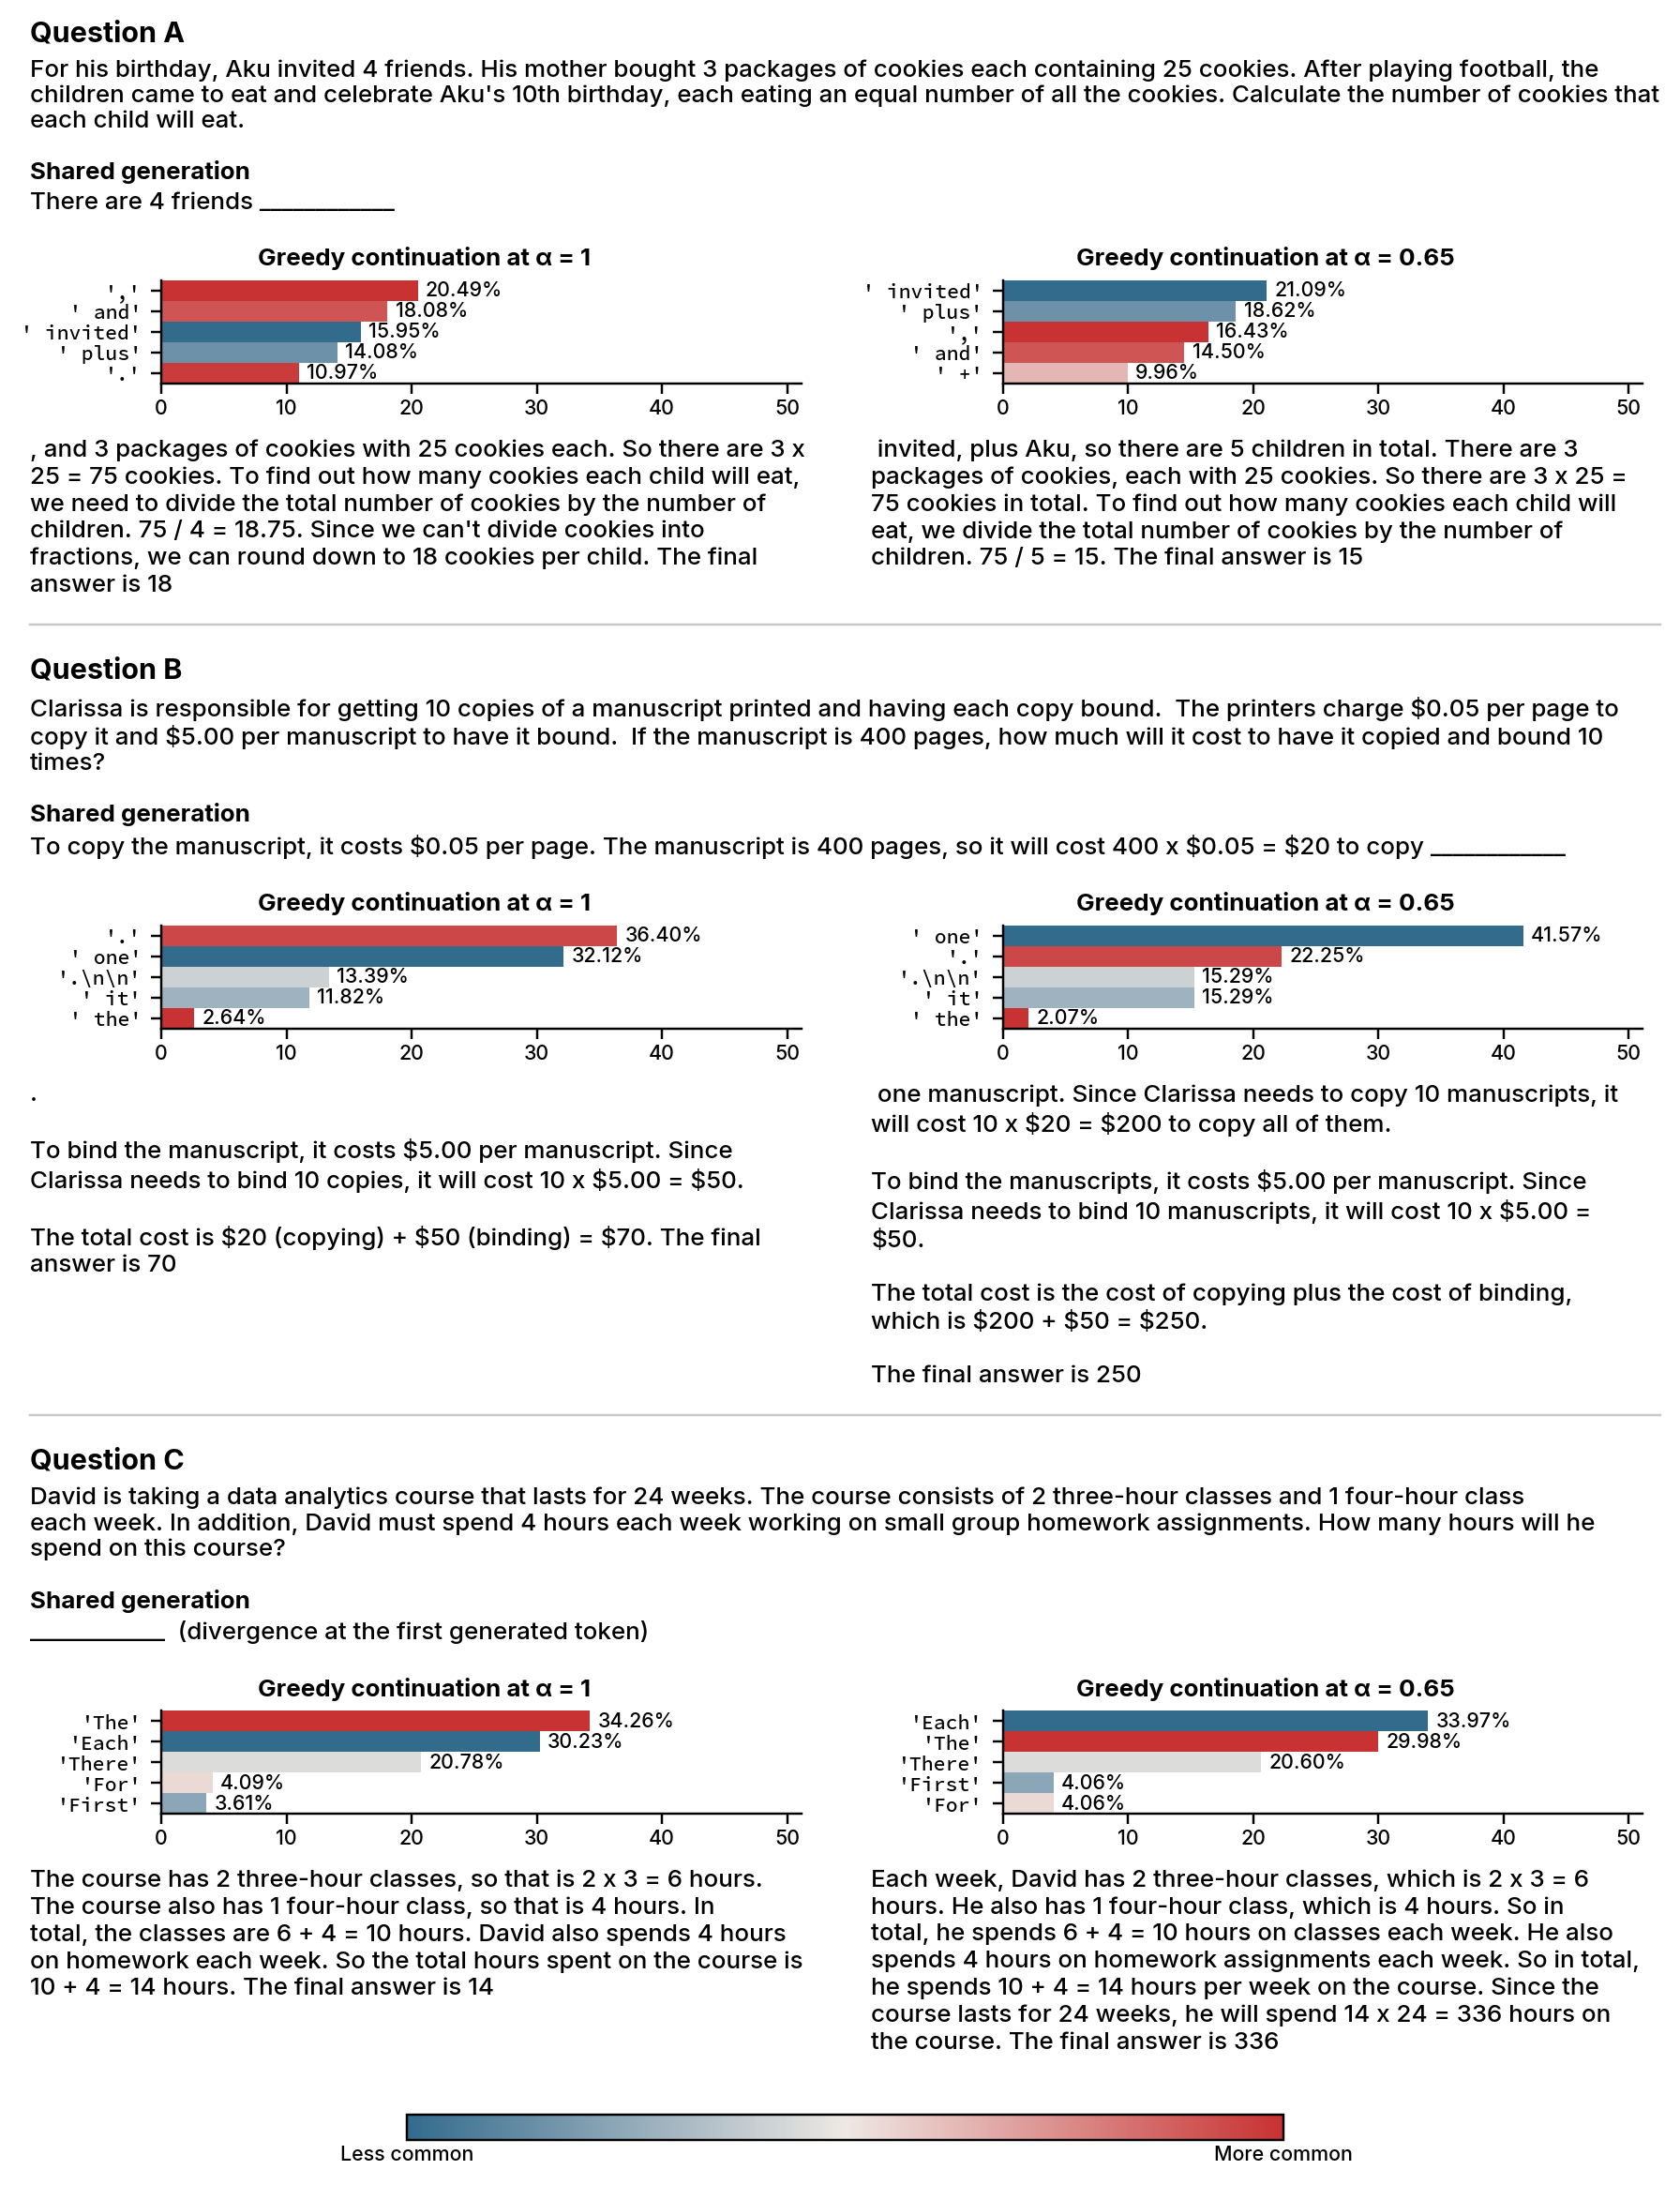

In [9]:
import importlib
import shutil

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from helpers import plot_reasoning_forks as forks
importlib.reload(forks)

# US-letter layout; `font` is the largest body size tried, and render_cases
# steps down in 0.5pt increments until the measured layout fits the page.
FORK_STYLE = dict(forks.FORK_STYLE)
FORK_STYLE.update(width=8.5, font=9.5, title_font=10,
                  question_wrap=118, prefix_wrap=118, path_wrap=62,
                  family="Inter", weight=500, mono_family="Source Code Pro",
                  red="#c83232", blue=STYLE["blue"], gray="#92979d")

# Merge the three scope-preservation examples into one tall figure.
figure = forks.render_cases(style=FORK_STYLE)
pdf_src = OUT / "fig4_reasoning_forks.pdf"
assert pdf_src.exists(), pdf_src
print(f"Saved appendix PDF: {pdf_src}")
plt.show()


In [ ]:
# Main-text figure: Question A alone at text width (5.5 in), with a small font
# and proportionally tighter vertical gaps to keep the figure short. Wider
# column gap and x-range keep percentages clear of the neighboring token labels.
MAIN_STYLE = dict(FORK_STYLE, width=5.5, font=7.5, gap_scale=7.5/9,
                  margin=.03, column_gap=.3, xlim_pad=1.35,
                  prompt_label="Prompt", fork_label="Fork at α = {}",
                  colorbar="vertical")
main_figure = forks.render_cases(cases=forks.CASES[:1], style=MAIN_STYLE,
                                 output_name="fig4_cookies_fork_main")
main_src = OUT / "fig4_cookies_fork_main.pdf"
print(f"Saved main-text PDF: {main_src}")
plt.show()

### Appendix caption notes

**Birthday cookies (case 36; manifest position 891).** The unmodified model divides the cookies among the four invited friends only and returns **18**. With reduced prior loading, the continuation explicitly adds Aku to the group of five children and reaches the reference answer of **15** cookies each. First differing token: comma → “invited”.

**Manuscript copies (case 26; manifest position 690).** Ten copies of a 400-page manuscript cost $0.05 per page plus $5 binding per copy. Shared prefix ends “400 x $0.05 = $20 to copy”. The baseline ends the sentence and charges $20 total for printing, plus $50 binding: **$70**. The reduced-prior continuation says **“one manuscript. Since Clarissa needs to copy 10 manuscripts”**, preserving the multiplicity and giving **$250**. First differing token: period → “one”.

**Course duration (case 47; manifest position 1123).** A 24-week course involves two three-hour classes, one four-hour class, and four homework hours each week. The baseline begins “The course has …” and reports **14 hours**. The reduced-prior continuation begins **“Each week, David has …”**, computes 14 hours per week, and multiplies by 24 to obtain **336 hours**. First differing token: “The” → “Each”.

All three are descriptive trajectory comparisons, not evidence that the first divergent token alone is necessary or sufficient. Together they illustrate preservation of participants, multiplicity, and temporal scope.
